# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Metrics are reported per isobath depth, mesh polygon, and buoy.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import validation as val
from utils.config import METAMODEL, load_goals, mda_max_points

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
print(f"Hs filter  : > {METAMODEL['site_filter']['hs_max']} m removed before PCA")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
candidates : [50, 450]
MDA max    : 450 (test cases = 500 - max)
Hs filter  : > 10.0 m removed before PCA


## 1. Fit

In [3]:
goal = "1"

# One goal — all MDA candidate sizes from config
mm.fit(goal, gp_epochs=1000, force_retrain=True)

2026-06-29 10:24:00,935 - Samoa.metamodel - WARNING - Goal 1: removed 29 site(s) (site_filter={'hs_max': 10.0, 'tp_min': 0.5}): 10m_17, 10m_30, 10m_80, 10m_92, 10m_98, 10m_99, 20m_93, 20m_94, 5m_1, 5m_10, 5m_11, 5m_27, 5m_42, 5m_55, 5m_56, 5m_69, 5m_76, 5m_79, 5m_87, 5m_88, Apia_11859, Apia_13871, Apia_1654, Apia_1655, Apia_1656, Apia_1660, Apia_1662, Apia_2661, Apia_4609
2026-06-29 10:24:01,006 - Samoa.metamodel - INFO - Goal 1: MDA fitted (450 train, 50 test)
2026-06-29 10:24:02,089 - PCA - WARNING - Using PCA
2026-06-29 10:24:02,828 - PCA - WARNING - Using 603 out of 603 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-06-29 10:24:02,834 - PCA - WARNING - Attribute pcs is an xarray Dataset / Dataarray and will be pickled!
2026-06-29 10:24:02,836 - Samoa.metamodel - INFO - Goal 1 / n=50: saved pca_hs_0.95_model.pkl
2026-06-29 10:24:02,837 - PCA - WARNING - Using PCA
2026-06-29 10:24:02,892 - PCA - WARNING

In [8]:
# All goals:
mm.fit_all(gp_epochs=1000)

2026-06-29 10:29:28,697 - Samoa.metamodel - INFO - Goal 1: loaded MDA (450 train, 50 test)
2026-06-29 10:29:28,698 - Samoa.metamodel - INFO - Goal 1 / n=50: loaded models
2026-06-29 10:29:28,781 - Samoa.metamodel - INFO - Goal 1 / n=450: loaded models
2026-06-29 10:29:28,884 - Samoa.metamodel - INFO - Goal 2: loaded MDA (450 train, 50 test)
2026-06-29 10:29:28,898 - PCA - WARNING - Using PCA
2026-06-29 10:29:29,614 - PCA - WARNING - Using 628 out of 628 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-06-29 10:29:29,619 - PCA - WARNING - Attribute pcs is an xarray Dataset / Dataarray and will be pickled!
2026-06-29 10:29:29,621 - Samoa.metamodel - INFO - Goal 2 / n=50: saved pca_hs_0.95_model.pkl
2026-06-29 10:29:29,621 - PCA - WARNING - Using PCA
2026-06-29 10:29:29,679 - PCA - WARNING - Using 628 out of 628 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop'

## 2. Validate

In [9]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep("9")
metrics.head()

2026-06-29 11:59:39,743 - Samoa.validation - INFO - Goal 9: validating n=50
2026-06-29 11:59:41,415 - Samoa.validation - INFO - Computed 27 validation metric row(s)
2026-06-29 11:59:41,416 - Samoa.validation - INFO - Goal 9: validating n=450
2026-06-29 11:59:43,406 - Samoa.validation - INFO - Computed 27 validation metric row(s)
2026-06-29 11:59:43,409 - Samoa.validation - INFO - Wrote /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/goal_09/validation_metrics.csv


,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2
0,9,50,50,"{'hs': 0.95, 'dir': 0.95}",5m,isobath,5m,hs,Hs,4100,-4.364943e-03,9.865121e-02,0.645266
1,9,50,50,"{'hs': 0.95, 'dir': 0.95}",5m,isobath,5m,tp,Tp,4100,1.559588e-08,8.104727e-07,1.000000
2,9,50,50,"{'hs': 0.95, 'dir': 0.95}",5m,isobath,5m,dir,Dir,4100,-7.682384e-01,1.525891e+01,0.944031
3,9,50,50,"{'hs': 0.95, 'dir': 0.95}",10m,isobath,10m,hs,Hs,5050,-5.600305e-03,8.001587e-02,0.718629
4,9,50,50,"{'hs': 0.95, 'dir': 0.95}",10m,isobath,10m,tp,Tp,5050,1.071783e-08,8.007420e-07,1.000000


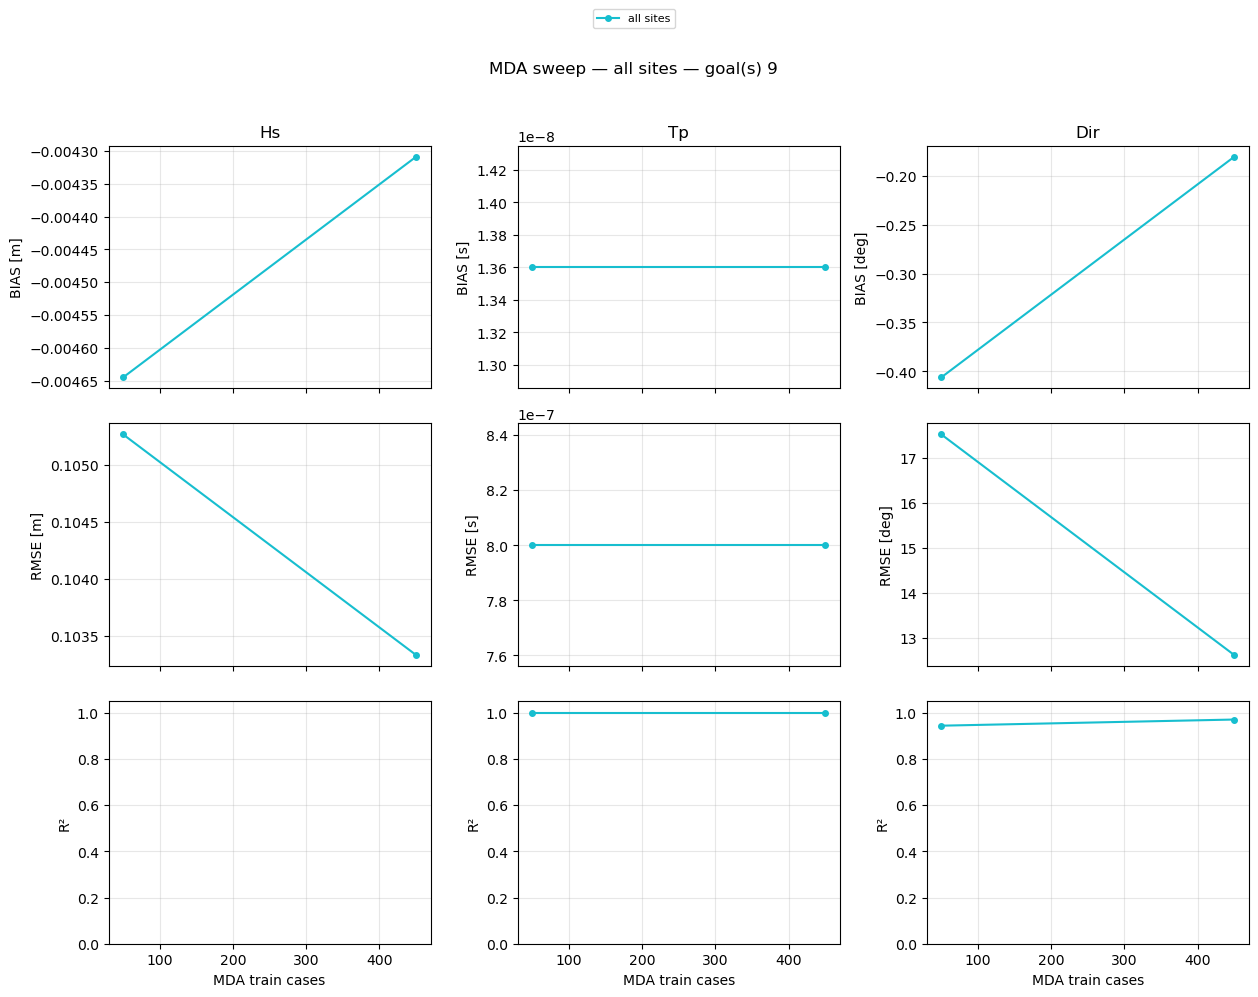

In [10]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3. Plot

In [12]:
n = 450  # MDA size to plot
result = val.validate("9", n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

2026-06-29 12:00:13,768 - Samoa.validation - INFO - Computed 27 validation metric row(s)


['5m',
 '10m',
 '20m',
 '50m',
 'Apia',
 'buoy_Apolima_Buoy',
 'buoy_Apolima_Javi_Buoy',
 'buoy_American_Samoa_Buoy',
 'buoy_Aunuu_Buoy']

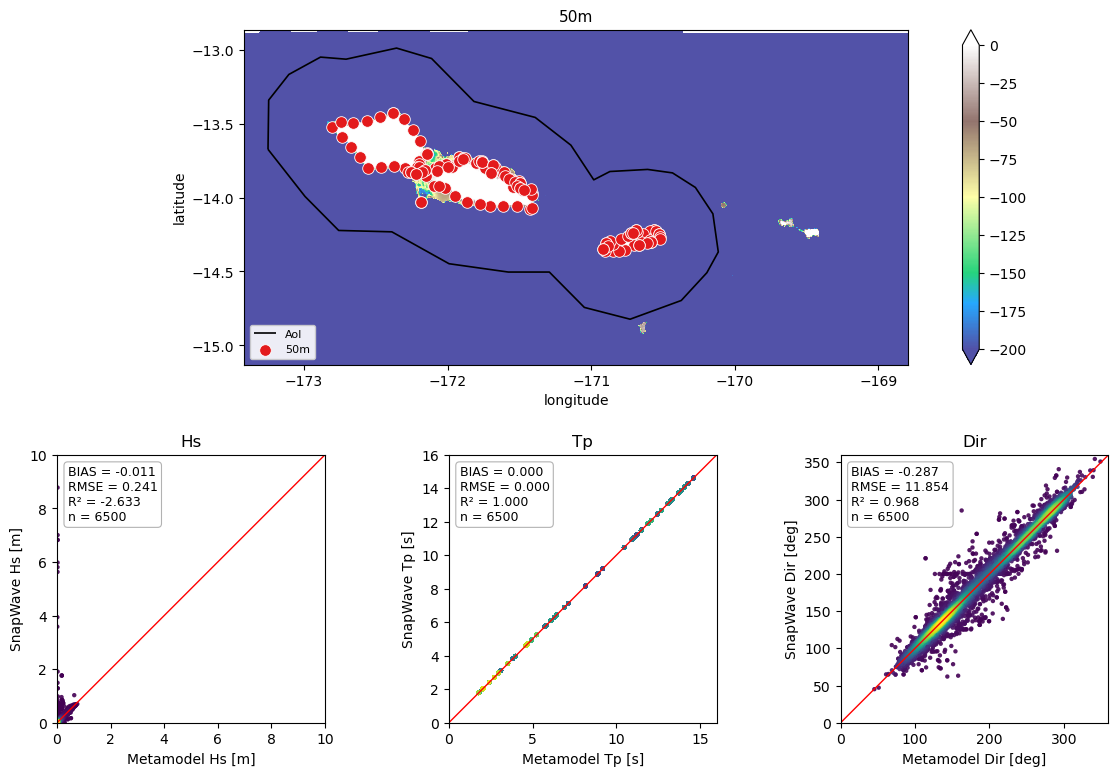

In [14]:
result.plot("50m")
plt.show()

In [ ]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(variables=["hs", "tp"]):
    plt.show()

## All goals

In [ ]:
all_metrics = val.sweep_all()
all_metrics

In [ ]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]